# Anscombe's Quartet Data Analysis Lab

## Data Science Tables Version

Instructor and Student Edition

## Learning Objectives
- Load data with Data Science Tables
- Compute descriptive statistics
- Visualize data with scatterplots and regression lines
- Compare summary statistics and visual patterns
- Understand why plotting data is essential

In [3]:
from datascience import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Part 1: Load the Dataset

In [4]:
quartet = Table.read_table("anscombe.csv")
quartet.show(10)
quartet

dataset,x,y
I,10,8.04
I,8,6.95
I,13,7.58
I,9,8.81
I,11,8.33
I,14,9.96
I,6,7.24
I,4,4.26
I,12,10.84
I,7,4.82


dataset,x,y
I,10,8.04
I,8,6.95
I,13,7.58
I,9,8.81
I,11,8.33
I,14,9.96
I,6,7.24
I,4,4.26
I,12,10.84
I,7,4.82


### Questions
1. How many observations are present?
2. How many datasets are included?

In [5]:
quartet.num_rows, quartet.labels

(44, ('dataset', 'x', 'y'))

## Part 2: Create Separate Tables

In [6]:
I = quartet.where("dataset", "I")
II = quartet.where("dataset", "II")
III = quartet.where("dataset", "III")
IV = quartet.where("dataset", "IV")

I, II, III, IV

(dataset | x    | y
 I       | 10   | 8.04
 I       | 8    | 6.95
 I       | 13   | 7.58
 I       | 9    | 8.81
 I       | 11   | 8.33
 I       | 14   | 9.96
 I       | 6    | 7.24
 I       | 4    | 4.26
 I       | 12   | 10.84
 I       | 7    | 4.82
 ... (1 rows omitted),
 dataset | x    | y
 II      | 10   | 9.14
 II      | 8    | 8.14
 II      | 13   | 8.74
 II      | 9    | 8.77
 II      | 11   | 9.26
 II      | 14   | 8.1
 II      | 6    | 6.13
 II      | 4    | 3.1
 II      | 12   | 9.13
 II      | 7    | 7.26
 ... (1 rows omitted),
 dataset | x    | y
 III     | 10   | 7.46
 III     | 8    | 6.77
 III     | 13   | 12.74
 III     | 9    | 7.11
 III     | 11   | 7.81
 III     | 14   | 8.84
 III     | 6    | 6.08
 III     | 4    | 5.39
 III     | 12   | 8.15
 III     | 7    | 6.42
 ... (1 rows omitted),
 dataset | x    | y
 IV      | 8    | 6.58
 IV      | 8    | 5.76
 IV      | 8    | 7.71
 IV      | 8    | 8.84
 IV      | 8    | 8.47
 IV      | 8    | 7.04
 IV      | 8    | 5.25


## Part 3: Display Each Dataset

In [7]:
I.show()
II.show()
III.show()
IV.show()

dataset,x,y
I,10,8.04
I,8,6.95
I,13,7.58
I,9,8.81
I,11,8.33
I,14,9.96
I,6,7.24
I,4,4.26
I,12,10.84
I,7,4.82


dataset,x,y
II,10,9.14
II,8,8.14
II,13,8.74
II,9,8.77
II,11,9.26
II,14,8.1
II,6,6.13
II,4,3.1
II,12,9.13
II,7,7.26


dataset,x,y
III,10,7.46
III,8,6.77
III,13,12.74
III,9,7.11
III,11,7.81
III,14,8.84
III,6,6.08
III,4,5.39
III,12,8.15
III,7,6.42


dataset,x,y
IV,8,6.58
IV,8,5.76
IV,8,7.71
IV,8,8.84
IV,8,8.47
IV,8,7.04
IV,8,5.25
IV,19,12.5
IV,8,5.56
IV,8,7.91


## Part 4: Descriptive Statistics

In [8]:
comparison = Table(["Dataset","Mean X","Mean Y","SD X","SD Y","Correlation"])

for name,data in zip(["I","II","III","IV"],[I,II,III,IV]):
    x=data.column("x")
    y=data.column("y")
    comparison=comparison.with_row([name,np.mean(x),np.mean(y),np.std(x),np.std(y),np.corrcoef(x,y)[0,1]])

comparison

Dataset,Mean X,Mean Y,SD X,SD Y,Correlation
I,9,7.50091,3.16228,1.93702,0.816421
II,9,7.50091,3.16228,1.93711,0.816237
III,9,7.5,3.16228,1.93593,0.816287
IV,9,7.50091,3.16228,1.93608,0.816521


### Student Questions
- What do you notice about the means?
- What do you notice about the correlations?

## Part 5: Scatterplots

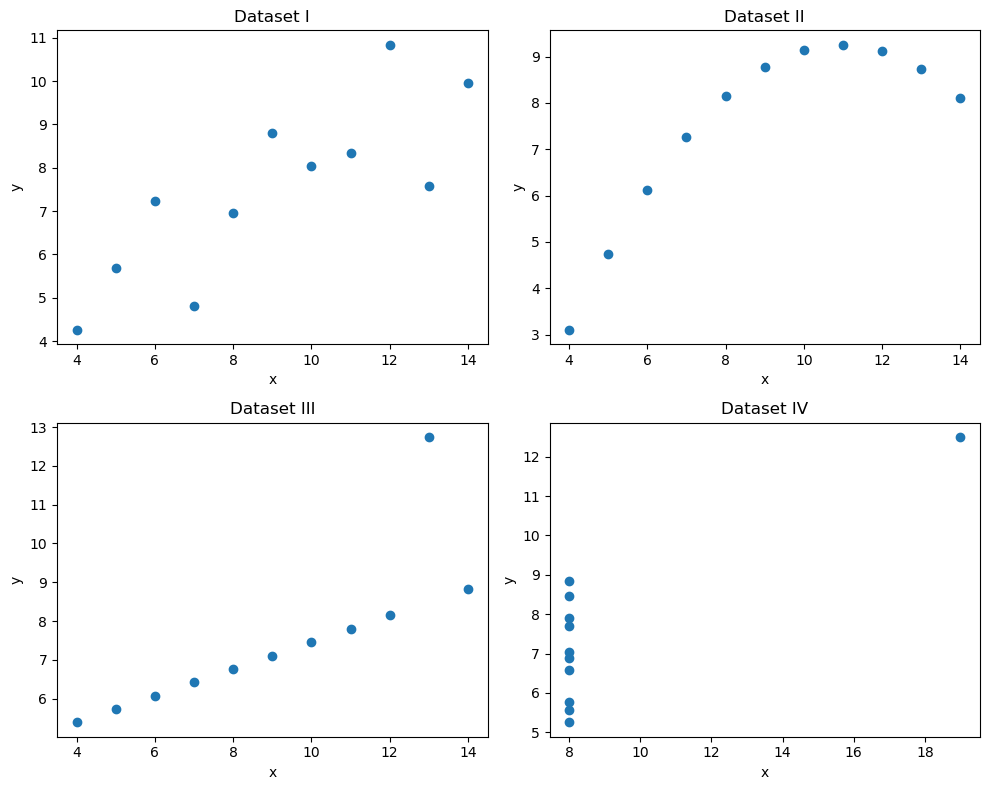

In [9]:
fig,axes=plt.subplots(2,2,figsize=(10,8))
datasets=[I,II,III,IV]
names=["I","II","III","IV"]
for ax,data,name in zip(axes.ravel(),datasets,names):
    ax.scatter(data.column("x"),data.column("y"))
    ax.set_title(f"Dataset {name}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

## Part 6: Linear Regression

In [10]:
def regression_parameters(x,y):
    slope=np.cov(x,y,bias=True)[0,1]/np.var(x)
    intercept=np.mean(y)-slope*np.mean(x)
    return slope,intercept

regression=Table(["Dataset","Slope","Intercept"])
for name,data in zip(["I","II","III","IV"],[I,II,III,IV]):
    x=data.column("x")
    y=data.column("y")
    slope,intercept=regression_parameters(x,y)
    regression=regression.with_row([name,slope,intercept])
regression

Dataset,Slope,Intercept
I,0.500091,3.00009
II,0.5,3.00091
III,0.499727,3.00245
IV,0.499909,3.00173


## Part 7: Scatterplots with Regression Lines

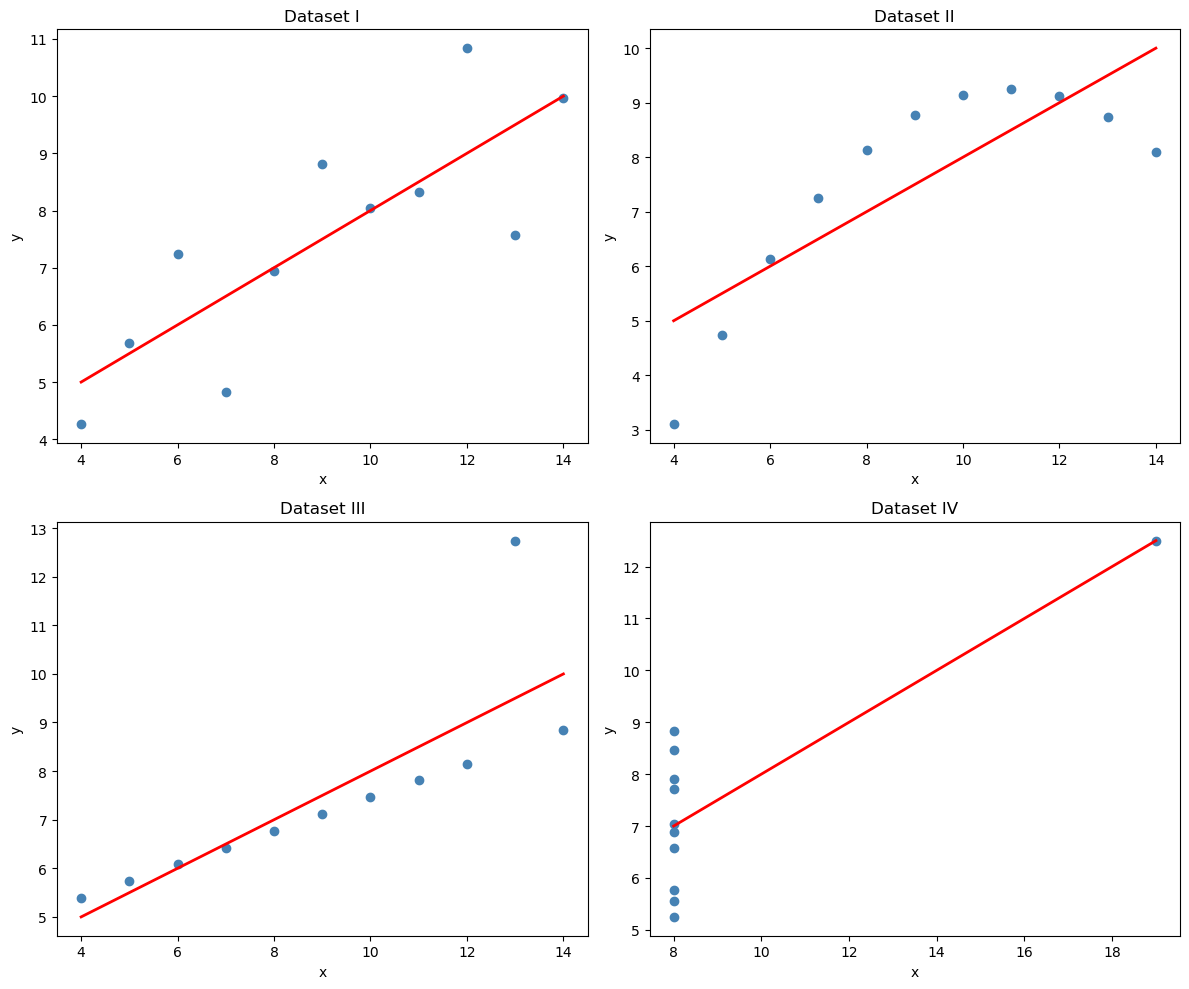

In [11]:
fig,axes=plt.subplots(2,2,figsize=(12,10))
datasets=[I,II,III,IV]
names=["I","II","III","IV"]
for ax,data,name in zip(axes.ravel(),datasets,names):
    x=data.column("x")
    y=data.column("y")
    slope,intercept=regression_parameters(x,y)
    xp=np.linspace(min(x),max(x),100)
    yp=intercept+slope*xp
    ax.scatter(x,y,color="steelblue")
    ax.plot(xp,yp,color="red",linewidth=2)
    ax.set_title(f"Dataset {name}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

## Part 8: Residual Analysis

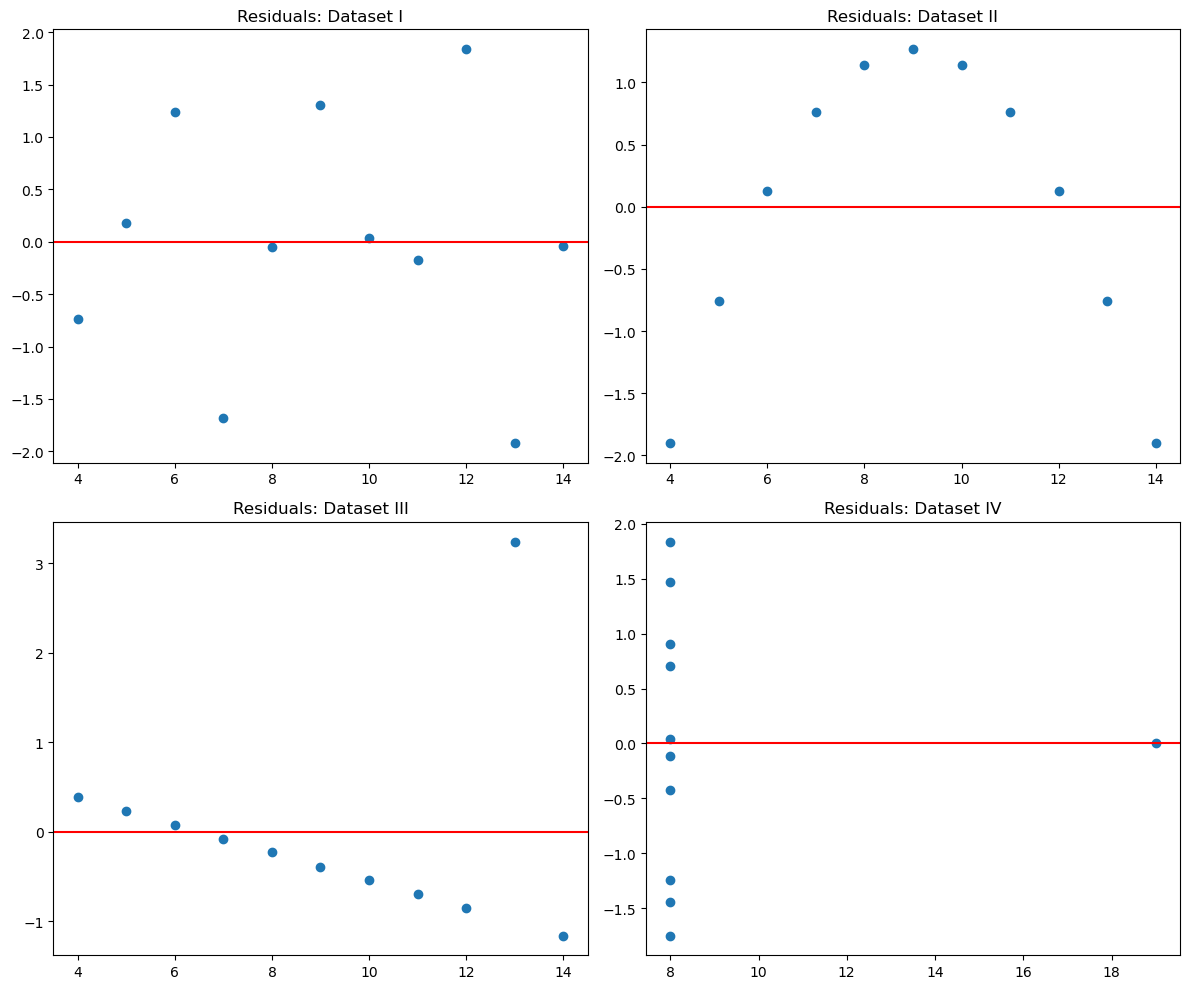

In [12]:
fig,axes=plt.subplots(2,2,figsize=(12,10))
for ax,data,name in zip(axes.ravel(),datasets,names):
    x=data.column("x")
    y=data.column("y")
    slope,intercept=regression_parameters(x,y)
    residuals=y-(intercept+slope*x)
    ax.scatter(x,residuals)
    ax.axhline(0,color="red")
    ax.set_title(f"Residuals: Dataset {name}")
plt.tight_layout()
plt.show()

## Part 9: Master Comparison Table

In [13]:
master=Table(["Dataset","Mean X","Mean Y","Correlation","Slope","Intercept"])
for name,data in zip(["I","II","III","IV"],[I,II,III,IV]):
    x=data.column("x")
    y=data.column("y")
    slope,intercept=regression_parameters(x,y)
    master=master.with_row([name,np.mean(x),np.mean(y),np.corrcoef(x,y)[0,1],slope,intercept])
master

Dataset,Mean X,Mean Y,Correlation,Slope,Intercept
I,9,7.50091,0.816421,0.500091,3.00009
II,9,7.50091,0.816237,0.5,3.00091
III,9,7.5,0.816287,0.499727,3.00245
IV,9,7.50091,0.816521,0.499909,3.00173


## Part 10: Guided Questions
1. Which dataset appears most linear?
2. Which dataset shows curvature?
3. Which contains an influential outlier?
4. Which contains a leverage point?
5. Why are visualizations important?